In [1]:
# MOUNT GOOGLE DRIVE
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# IMPORT LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow Version:", tf.__version__)


TensorFlow Version: 2.20.0


In [3]:
# LOAD DATASET
dataset_path = "/content/drive/MyDrive/diabetes.csv"

df = pd.read_csv(dataset_path)

print(df.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [4]:
# DATA EXPLORATION
print("\nDataset Shape:")
print(df.shape)

print("\nDataset Info:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nClass Distribution:")
print(df['Outcome'].value_counts())


Dataset Shape:
(768, 9)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None

Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         

In [5]:
# Columns that should not contain zero
cols = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

In [6]:
# Count zeros before replacement
print("\nInvalid Zero Values:")

for col in cols:
    print(col, (df[col] == 0).sum())


Invalid Zero Values:
Glucose 5
BloodPressure 35
SkinThickness 227
Insulin 374
BMI 11


In [7]:
# Replace zeros with NaN
df[cols] = df[cols].replace(0, np.nan)

In [8]:
# Fill NaN using median

for col in cols:
    df[col] = df[col].fillna(df[col].median())

print("\nMissing values after imputation:")
print(df.isnull().sum())


Missing values after imputation:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [9]:
# FEATURES AND TARGET
X = df.drop("Outcome", axis=1)

y = df["Outcome"]

In [10]:
# TRAIN TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples :", len(X_test))


Training Samples: 614
Testing Samples : 154


In [11]:
# FEATURE SCALING
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [12]:
# EARLY STOPPING
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

In [13]:
#  MODEL WITHOUT BATCH NORMALIZATION
model_without_bn = Sequential([

    Dense(128, activation='relu', input_shape=(8,)),
    Dropout(0.3),

    Dense(64, activation='relu'),
    Dropout(0.3),

    Dense(32, activation='relu'),
    Dropout(0.2),

    Dense(1, activation='sigmoid')

])

model_without_bn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model_without_bn.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,521 (45.00 KB)

 Trainable params: 11,521 (45.00 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
#  TRAIN MODEL WITHOUT BN
history_without_bn = model_without_bn.fit(

    X_train,
    y_train,

    validation_split=0.20,

    epochs=100,

    batch_size=32,

    callbacks=[early_stop],

    verbose=1
)

Epoch 1/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.6029 - loss: 0.6736 - val_accuracy: 0.6667 - val_loss: 0.6267
Epoch 2/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6741 - loss: 0.6025 - val_accuracy: 0.7480 - val_loss: 0.5411
Epoch 3/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7312 - loss: 0.5350 - val_accuracy: 0.7805 - val_loss: 0.4860
Epoch 4/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7556 - loss: 0.4940 - val_accuracy: 0.7967 - val_loss: 0.4549
Epoch 5/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7719 - loss: 0.4684 - val_accuracy: 0.8130 - val_loss: 0.4381
Epoch 6/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7637 - loss: 0.4618 - val_accuracy: 0.8130 - val_loss: 0.4296
Epoch 7/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7637 - loss: 0.4653 - val_accuracy: 0.8211 - val_loss: 0.4252
Epoch 8/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7821 - loss: 0.4558 - val_accuracy: 0.

In [15]:
# EVALUATE MODEL WITHOUT BN
y_pred_prob = model_without_bn.predict(X_test)

y_pred = (y_pred_prob > 0.5).astype(int)

acc1 = accuracy_score(y_test, y_pred)
prec1 = precision_score(y_test, y_pred)
rec1 = recall_score(y_test, y_pred)
f11 = f1_score(y_test, y_pred)

print("\nWITHOUT BATCH NORMALIZATION")
print("Accuracy :", acc1)
print("Precision:", prec1)
print("Recall   :", rec1)
print("F1 Score :", f11)

print("\nClassification Report")
print(classification_report(y_test, y_pred))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step

WITHOUT BATCH NORMALIZATION
Accuracy : 0.7337662337662337
Precision: 0.6226415094339622
Recall   : 0.6111111111111112
F1 Score : 0.616822429906542

Classification Report
              precision    recall  f1-score   support

           0       0.79      0.80      0.80       100
           1       0.62      0.61      0.62        54

    accuracy                           0.73       154
   macro avg       0.71      0.71      0.71       154
weighted avg       0.73      0.73      0.73       154



In [16]:
# MODEL WITH BATCH NORMALIZATION
model_with_bn = Sequential([

    Dense(128, activation='relu', input_shape=(8,)),
    BatchNormalization(),
    Dropout(0.3),

    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),

    Dense(1, activation='sigmoid')

])

model_with_bn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model_with_bn.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 128)            │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,417 (48.50 KB)

 Trainable params: 11,969 (46.75 KB)

 Non-trainable params: 448 (1.75 KB)

In [17]:
# TRAIN MODEL WITH BN
history_with_bn = model_with_bn.fit(

    X_train,
    y_train,

    validation_split=0.20,

    epochs=100,

    batch_size=32,

    callbacks=[early_stop],

    verbose=1
)

Epoch 1/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.5458 - loss: 0.7816 - val_accuracy: 0.7886 - val_loss: 0.5922
Epoch 2/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6741 - loss: 0.6278 - val_accuracy: 0.7724 - val_loss: 0.5660
Epoch 3/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7271 - loss: 0.5787 - val_accuracy: 0.7805 - val_loss: 0.5501
Epoch 4/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7006 - loss: 0.5741 - val_accuracy: 0.8049 - val_loss: 0.5385
Epoch 5/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7230 - loss: 0.5642 - val_accuracy: 0.8211 - val_loss: 0.5267
Epoch 6/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7536 - loss: 0.5143 - val_accuracy: 0.7886 - val_loss: 0.5124
Epoch 7/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7413 - loss: 0.5304 - val_accuracy: 0.7886 - val_loss: 0.5010
Epoch 8/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7699 - loss: 0.4837 - val_accuracy: 0.7967 - 

In [18]:
# EVALUATE MODEL WITH BN
y_pred_prob_bn = model_with_bn.predict(X_test)

y_pred_bn = (y_pred_prob_bn > 0.5).astype(int)

acc2 = accuracy_score(y_test, y_pred_bn)
prec2 = precision_score(y_test, y_pred_bn)
rec2 = recall_score(y_test, y_pred_bn)
f12 = f1_score(y_test, y_pred_bn)

print("\nWITH BATCH NORMALIZATION")
print("Accuracy :", acc2)
print("Precision:", prec2)
print("Recall   :", rec2)
print("F1 Score :", f12)

print("\nClassification Report")
print(classification_report(y_test, y_pred_bn))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step

WITH BATCH NORMALIZATION
Accuracy : 0.7337662337662337
Precision: 0.6274509803921569
Recall   : 0.5925925925925926
F1 Score : 0.6095238095238096

Classification Report
              precision    recall  f1-score   support

           0       0.79      0.81      0.80       100
           1       0.63      0.59      0.61        54

    accuracy                           0.73       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.73      0.73       154



In [19]:
# COMPARISON TABLE
comparison = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],

    "Without BatchNorm": [
        acc1,
        prec1,
        rec1,
        f11
    ],

    "With BatchNorm": [
        acc2,
        prec2,
        rec2,
        f12
    ]
})

print("\nComparison Table")
print(comparison)


Comparison Table
      Metric  Without BatchNorm  With BatchNorm
0   Accuracy           0.733766        0.733766
1  Precision           0.622642        0.627451
2     Recall           0.611111        0.592593
3   F1 Score           0.616822        0.609524


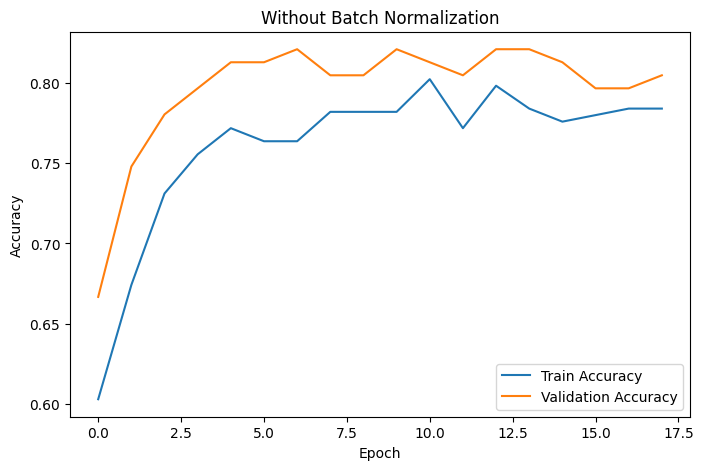

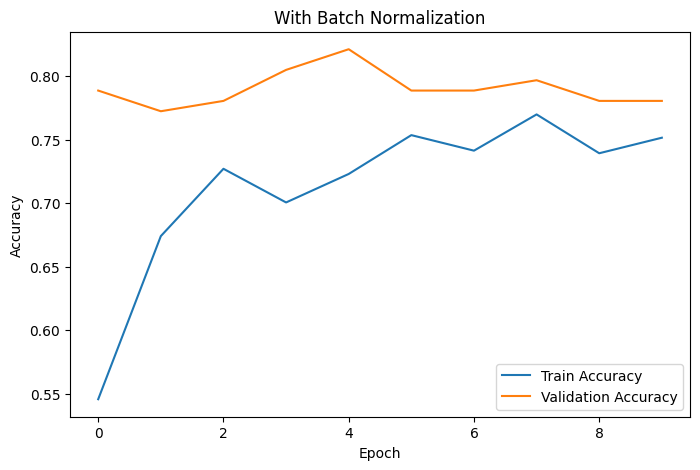

In [20]:
# ACCURACY CURVES
plt.figure(figsize=(8,5))

plt.plot(
    history_without_bn.history['accuracy'],
    label='Train Accuracy'
)

plt.plot(
    history_without_bn.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title("Without Batch Normalization")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


plt.figure(figsize=(8,5))

plt.plot(
    history_with_bn.history['accuracy'],
    label='Train Accuracy'
)

plt.plot(
    history_with_bn.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title("With Batch Normalization")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

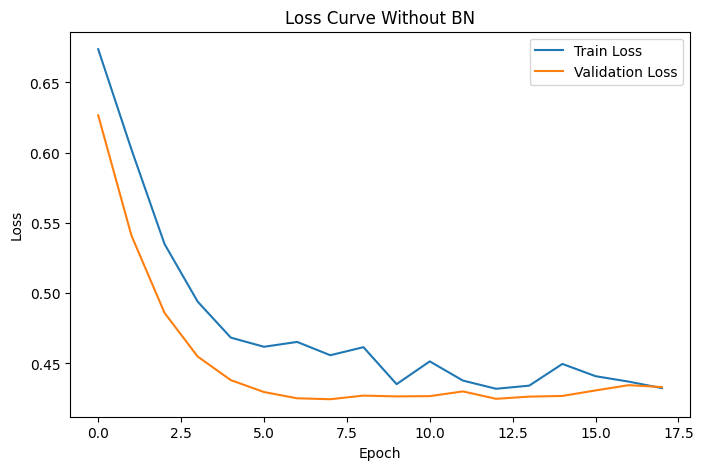

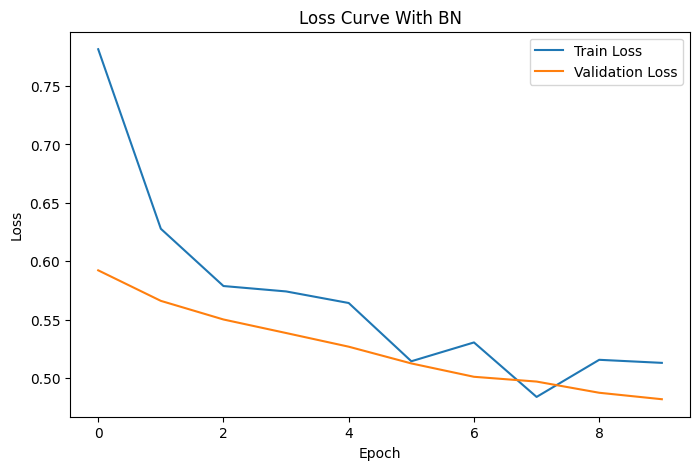

In [21]:
# LOSS CURVES
plt.figure(figsize=(8,5))

plt.plot(
    history_without_bn.history['loss'],
    label='Train Loss'
)

plt.plot(
    history_without_bn.history['val_loss'],
    label='Validation Loss'
)

plt.title("Loss Curve Without BN")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()


plt.figure(figsize=(8,5))

plt.plot(
    history_with_bn.history['loss'],
    label='Train Loss'
)

plt.plot(
    history_with_bn.history['val_loss'],
    label='Validation Loss'
)

plt.title("Loss Curve With BN")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()